In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/credit_risk_dataset.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:

# Dataset information
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
df.describe()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB

Dataset S

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [3]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Missing value percentages
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check loan status distribution
print("\nLoan Status Distribution:")
print(df['loan_status'].value_counts())

# Check loan status percentage
print("\nLoan Status Percentage:")
print(df['loan_status'].value_counts(normalize=True) * 100)


Missing Values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Missing Value Percentage:
person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.75
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.56
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

Duplicate Records:
165

Loan Status Distribution:
loan_status
0    25473
1     7108
Name

In [4]:

# Create a working copy
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Duplicates removed:", df.shape[0] - df_clean.shape[0])
print("New dataset shape:", df_clean.shape)


Duplicates removed: 165
New dataset shape: (32416, 12)


In [5]:

# Fill missing values using median

df_clean['person_emp_length'] = (
    df_clean['person_emp_length'].fillna(
        df_clean['person_emp_length'].median()
    )
)

df_clean['loan_int_rate'] = (
    df_clean['loan_int_rate'].fillna(
        df_clean['loan_int_rate'].median()
    )
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())


Missing values after cleaning:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [6]:

print("Final dataset shape:", df_clean.shape)

print("Total missing values:", df_clean.isnull().sum().sum())

print("Total duplicate rows:", df_clean.duplicated().sum())


Final dataset shape: (32416, 12)
Total missing values: 0
Total duplicate rows: 0


Loan Status Counts:
loan_status
0    25327
1     7089
Name: count, dtype: int64

Loan Status Percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


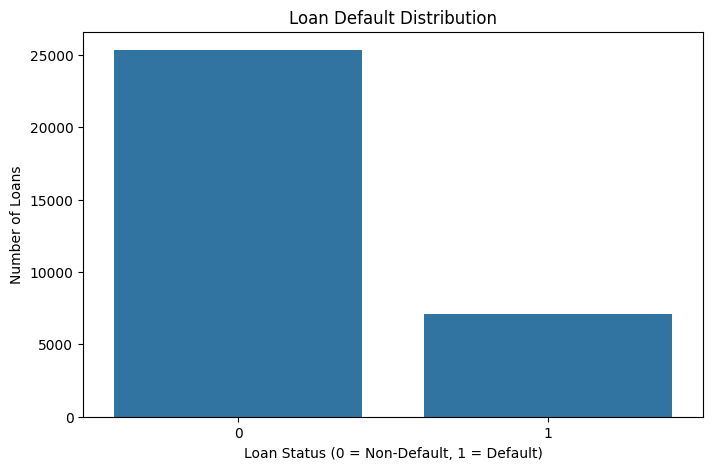

In [7]:

# Loan status distribution after cleaning

print("Loan Status Counts:")
print(df_clean['loan_status'].value_counts())

print("\nLoan Status Percentage:")
print(
    (df_clean['loan_status'].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='loan_status')

plt.title('Loan Default Distribution')
plt.xlabel('Loan Status (0 = Non-Default, 1 = Default)')
plt.ylabel('Number of Loans')

plt.show()


Default Rate by Loan Grade:
loan_grade
G    98.44
F    70.54
E    64.49
D    59.06
C    20.75
B    16.32
A     9.96
Name: loan_status, dtype: float64


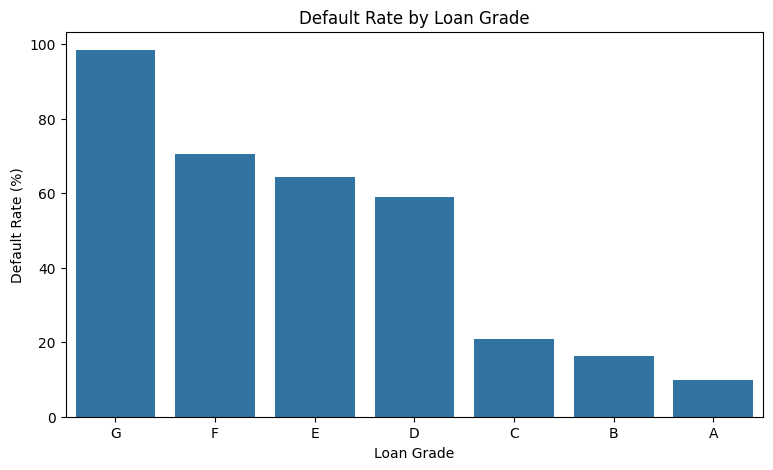

In [8]:

grade_risk = (
    df_clean.groupby('loan_grade')['loan_status']
    .mean() * 100
)

grade_risk = grade_risk.sort_values(ascending=False)

print("Default Rate by Loan Grade:")
print(grade_risk.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=grade_risk.index,
    y=grade_risk.values
)

plt.title('Default Rate by Loan Grade')
plt.xlabel('Loan Grade')
plt.ylabel('Default Rate (%)')

plt.show()


In [9]:

grade_analysis = df_clean.groupby('loan_grade').agg(
    Total_Loans=('loan_status', 'count'),
    Defaulted_Loans=('loan_status', 'sum'),
    Default_Rate=('loan_status', 'mean')
)

grade_analysis['Default_Rate'] = (
    grade_analysis['Default_Rate'] * 100
).round(2)

print(grade_analysis.sort_values(
    by='Default_Rate',
    ascending=False
))


            Total_Loans  Defaulted_Loans  Default_Rate
loan_grade                                            
G                    64               63         98.44
F                   241              170         70.54
E                   963              621         64.49
D                  3620             2138         59.06
C                  6438             1336         20.75
B                 10387             1695         16.32
A                 10703             1066          9.96


                   Total_Loans  Defaulted_Loans  Default_Rate
loan_intent                                                  
DEBTCONSOLIDATION         5189             1488         28.68
MEDICAL                   6042             1617         26.76
HOMEIMPROVEMENT           3594              940         26.15
PERSONAL                  5498             1094         19.90
EDUCATION                 6411             1106         17.25
VENTURE                   5682              844         14.85


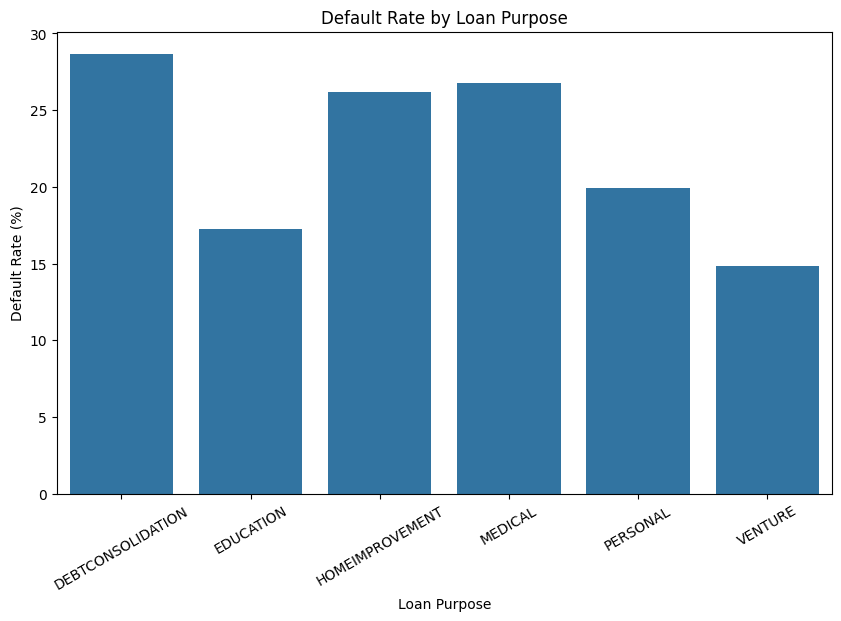

In [10]:

# Default rate by loan purpose

purpose_analysis = df_clean.groupby('loan_intent').agg(
    Total_Loans=('loan_status', 'count'),
    Defaulted_Loans=('loan_status', 'sum'),
    Default_Rate=('loan_status', 'mean')
)

purpose_analysis['Default_Rate'] = (
    purpose_analysis['Default_Rate'] * 100
).round(2)

print(purpose_analysis.sort_values(
    by='Default_Rate',
    ascending=False
))

# Visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=purpose_analysis.reset_index(),
    x='loan_intent',
    y='Default_Rate'
)

plt.title('Default Rate by Loan Purpose')
plt.xlabel('Loan Purpose')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=30)

plt.show()


In [11]:

purpose_analysis = df_clean.groupby('loan_intent').agg(
    Total_Loans=('loan_status', 'count'),
    Defaulted_Loans=('loan_status', 'sum'),
    Default_Rate=('loan_status', 'mean')
)

purpose_analysis['Default_Rate'] *= 100

print(purpose_analysis.round(2).sort_values(
    by='Default_Rate',
    ascending=False
))


                   Total_Loans  Defaulted_Loans  Default_Rate
loan_intent                                                  
DEBTCONSOLIDATION         5189             1488         28.68
MEDICAL                   6042             1617         26.76
HOMEIMPROVEMENT           3594              940         26.15
PERSONAL                  5498             1094         19.90
EDUCATION                 6411             1106         17.25
VENTURE                   5682              844         14.85


In [12]:

# Average income and loan amount by loan status

income_analysis = df_clean.groupby('loan_status').agg(
    Average_Income=('person_income', 'mean'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Loan_Income_Ratio=('loan_percent_income', 'mean')
)

print(income_analysis.round(2))


             Average_Income  Average_Loan_Amount  Average_Loan_Income_Ratio
loan_status                                                                
0                  70849.12              9240.16                       0.15
1                  49094.50             10857.48                       0.25


In [13]:

# Interest rate analysis by loan status

interest_analysis = df_clean.groupby('loan_status').agg(
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Median_Interest_Rate=('loan_int_rate', 'median'),
    Average_Credit_History=('cb_person_cred_hist_length', 'mean')
)

print(interest_analysis.round(2))


             Average_Interest_Rate  Median_Interest_Rate  \
loan_status                                                
0                            10.49                 10.99   
1                            12.88                 12.99   

             Average_Credit_History  
loan_status                          
0                              5.85  
1                              5.68  


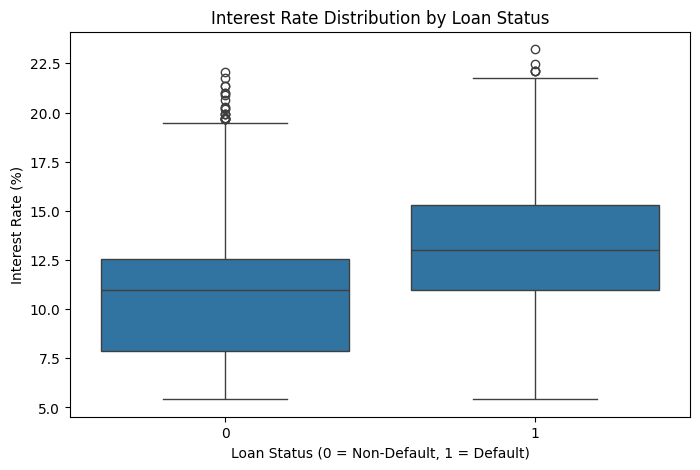

In [14]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='loan_status',
    y='loan_int_rate'
)

plt.title('Interest Rate Distribution by Loan Status')
plt.xlabel('Loan Status (0 = Non-Default, 1 = Default)')
plt.ylabel('Interest Rate (%)')

plt.show()


In [15]:

# STEP 1: Data Preprocessing

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separate features and target
X = df_clean.drop(columns=['loan_status'])
y = df_clean['loan_status']

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:", list(numeric_features))
print("Categorical Features:", list(categorical_features))

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Fit on training data, transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing Completed Successfully!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Numerical Features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical Features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Preprocessing Completed Successfully!
Training Data Shape: (25932, 26)
Testing Data Shape: (6484, 26)
Training Target Shape: (25932,)
Testing Target Shape: (6484,)


In [16]:

# STEP 2: Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_processed, y_train)

# Make predictions
y_pred = lr_model.predict(X_test_processed)
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# Evaluate model
print("LOGISTIC REGRESSION RESULTS")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


LOGISTIC REGRESSION RESULTS
----------------------------
Accuracy: 0.8691
Precision: 0.7728
Recall: 0.5684
F1 Score: 0.655
ROC-AUC: 0.868

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      5066
           1       0.77      0.57      0.66      1418

    accuracy                           0.87      6484
   macro avg       0.83      0.76      0.79      6484
weighted avg       0.86      0.87      0.86      6484


Confusion Matrix:
[[4829  237]
 [ 612  806]]


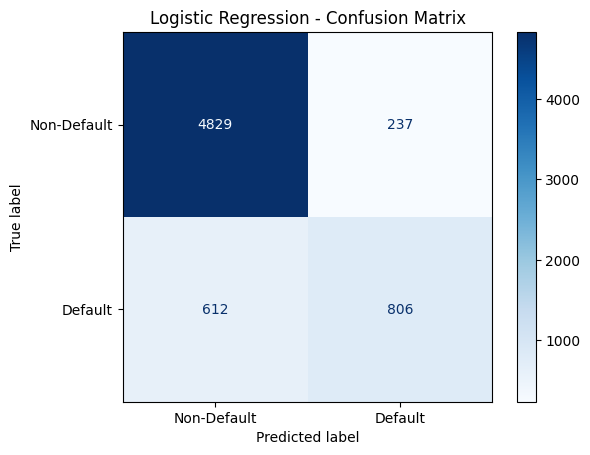

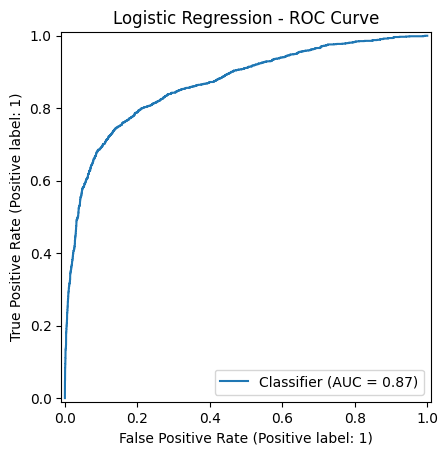

Baseline metrics saved successfully!
{'Accuracy': 0.8690623072177668, 'Precision': 0.7727708533077661, 'Recall': 0.5684062059238364, 'F1 Score': 0.6550182852498985, 'ROC-AUC': np.float64(0.867960829602143)}


In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Save baseline metrics for future comparison
baseline_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Non-Default', 'Default'],
    cmap='Blues'
)
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title('Logistic Regression - ROC Curve')
plt.show()

print("Baseline metrics saved successfully!")
print(baseline_metrics)


In [18]:

# Logistic Regression with Class Weight Balancing

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# Train balanced Logistic Regression model
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_balanced.fit(X_train_processed, y_train)

# Predictions
y_pred_balanced = lr_balanced.predict(X_test_processed)
y_prob_balanced = lr_balanced.predict_proba(X_test_processed)[:, 1]

# Evaluate model
print("BALANCED LOGISTIC REGRESSION RESULTS")
print("------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_balanced), 4))
print("Recall:", round(recall_score(y_test, y_pred_balanced), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_balanced), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_balanced), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))


BALANCED LOGISTIC REGRESSION RESULTS
------------------------------------
Accuracy: 0.8151
Precision: 0.5556
Recall: 0.7722
F1 Score: 0.6462
ROC-AUC: 0.8696

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.87      5066
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6484
   macro avg       0.74      0.80      0.76      6484
weighted avg       0.85      0.82      0.82      6484


Confusion Matrix:
[[4190  876]
 [ 323 1095]]


In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluation
print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


RANDOM FOREST RESULTS
---------------------
Accuracy: 0.9321
Precision: 0.9562
Recall: 0.7228
F1 Score: 0.8233
ROC-AUC: 0.931

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5066
           1       0.96      0.72      0.82      1418

    accuracy                           0.93      6484
   macro avg       0.94      0.86      0.89      6484
weighted avg       0.93      0.93      0.93      6484


Confusion Matrix:
[[5019   47]
 [ 393 1025]]


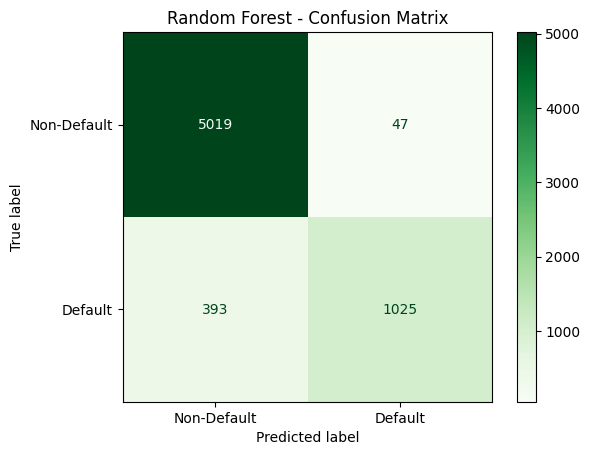

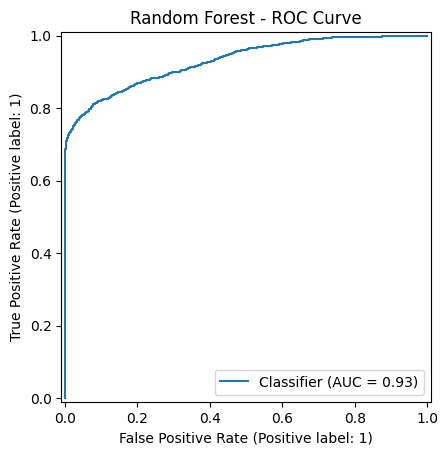

In [20]:

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=['Non-Default', 'Default'],
    cmap='Greens'
)

plt.title('Random Forest - Confusion Matrix')
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf
)

plt.title('Random Forest - ROC Curve')
plt.show()


In [21]:
from sklearn.metrics import roc_auc_score

print("Random Forest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest ROC-AUC: 0.9309911704290391


                                Feature  Importance
5              num__loan_percent_income    0.208772
1                    num__person_income    0.158196
4                    num__loan_int_rate    0.126242
3                        num__loan_amnt    0.074992
20                    cat__loan_grade_D    0.060223
2                num__person_emp_length    0.046222
10      cat__person_home_ownership_RENT    0.046210
0                       num__person_age    0.040301
6       num__cb_person_cred_hist_length    0.031188
17                    cat__loan_grade_A    0.025608
7   cat__person_home_ownership_MORTGAGE    0.022680
19                    cat__loan_grade_C    0.019148
9        cat__person_home_ownership_OWN    0.017495
13     cat__loan_intent_HOMEIMPROVEMENT    0.015114
21                    cat__loan_grade_E    0.014174


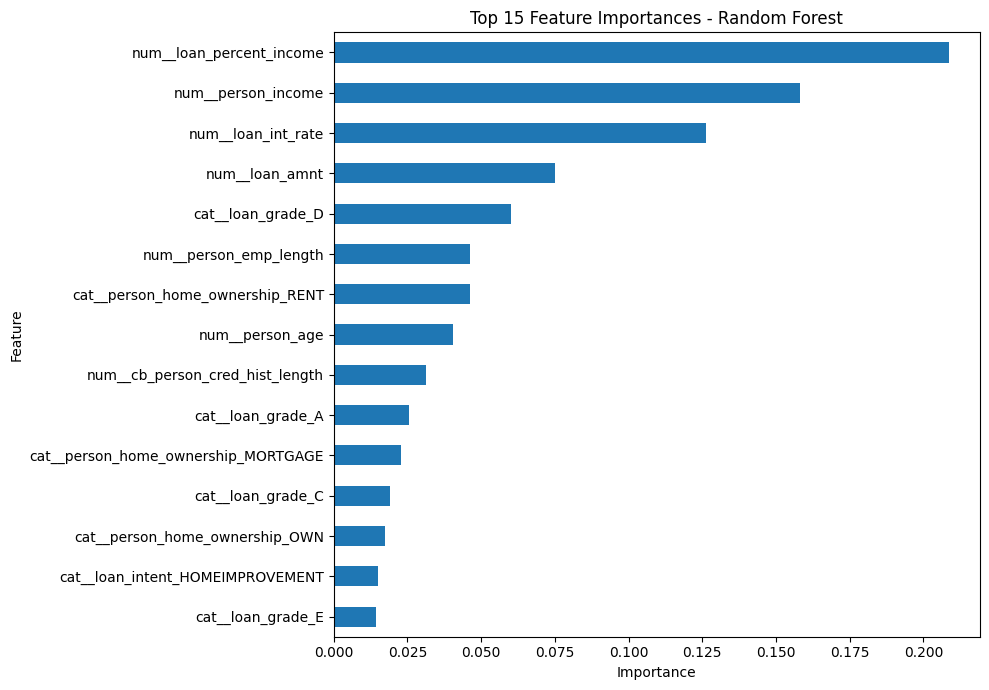

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

print(importance_df.head(15))

importance_df.head(15).sort_values(
    'Importance'
).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(10, 7),
    legend=False
)

plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [23]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

perm_result = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': perm_result.importances_mean
}).sort_values(by='Importance', ascending=False)

print(permutation_df.head(15).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


                         Feature  Importance
        num__loan_percent_income    0.074802
              num__person_income    0.047778
               cat__loan_grade_A    0.019447
              num__loan_int_rate    0.016753
 cat__person_home_ownership_RENT    0.013865
               cat__loan_grade_D    0.012005
        cat__loan_intent_VENTURE    0.010564
               cat__loan_grade_B    0.009566
  cat__person_home_ownership_OWN    0.009350
cat__loan_intent_HOMEIMPROVEMENT    0.008622
          num__person_emp_length    0.006435
               cat__loan_grade_C    0.006240
                  num__loan_amnt    0.004888
                 num__person_age    0.004828
cat__cb_person_default_on_file_N    0.003542


In [24]:
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [0.8691, 0.8151, 0.9321],
    'Precision': [0.7728, 0.5556, 0.9562],
    'Recall': [0.5684, 0.7722, 0.7228],
    'F1 Score': [0.6550, 0.6462, 0.8233],
    'ROC-AUC': [0.8680, 0.8696, 0.9310]
})

print(comparison.to_string(index=False))

                       Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
         Logistic Regression    0.8691     0.7728  0.5684    0.6550   0.8680
Balanced Logistic Regression    0.8151     0.5556  0.7722    0.6462   0.8696
               Random Forest    0.9321     0.9562  0.7228    0.8233   0.9310


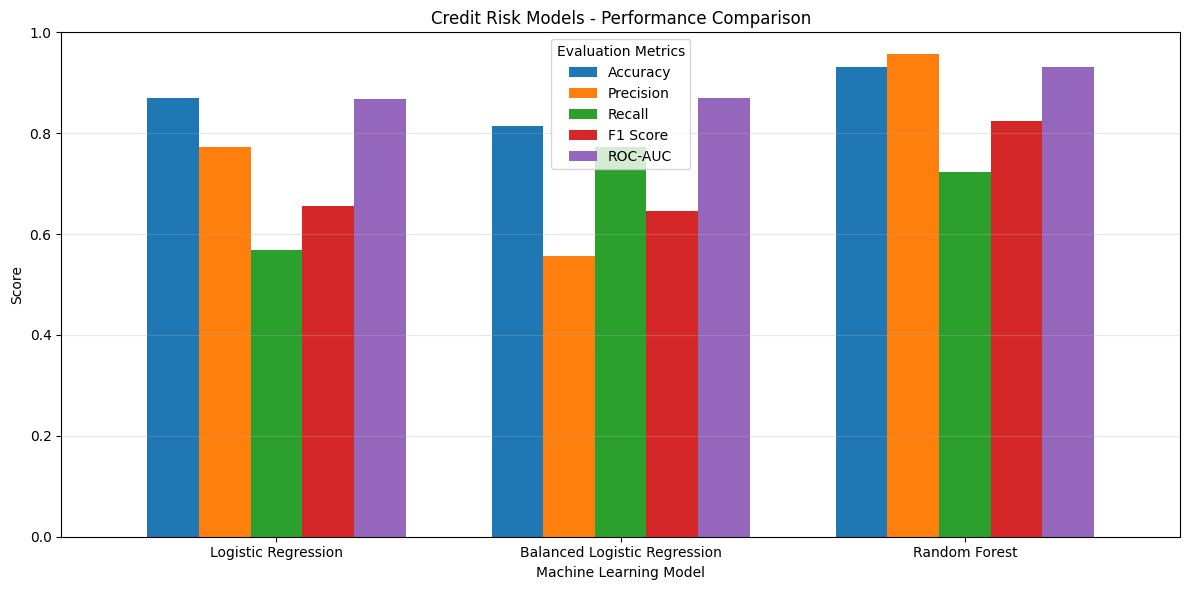

In [25]:
import matplotlib.pyplot as plt

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.75
)

plt.title('Credit Risk Models - Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Machine Learning Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Business insights from the cleaned dataset

print("CREDIT RISK BUSINESS INSIGHTS")
print("-" * 45)

default_rate = df_clean['loan_status'].mean() * 100

print(f"Overall default rate: {default_rate:.2f}%")

print("\nDefault rate by loan grade:")
print(
    (df_clean.groupby('loan_grade')['loan_status'].mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print("\nDefault rate by loan purpose:")
print(
    (df_clean.groupby('loan_intent')['loan_status'].mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print("\nAverage loan-to-income ratio by loan status:")
print(
    df_clean.groupby('loan_status')['loan_percent_income']
    .mean()
    .round(3)
)

CREDIT RISK BUSINESS INSIGHTS
---------------------------------------------
Overall default rate: 21.87%

Default rate by loan grade:
loan_grade
G    98.44
F    70.54
E    64.49
D    59.06
C    20.75
B    16.32
A     9.96
Name: loan_status, dtype: float64

Default rate by loan purpose:
loan_intent
DEBTCONSOLIDATION    28.68
MEDICAL              26.76
HOMEIMPROVEMENT      26.15
PERSONAL             19.90
EDUCATION            17.25
VENTURE              14.85
Name: loan_status, dtype: float64

Average loan-to-income ratio by loan status:
loan_status
0    0.149
1    0.247
Name: loan_percent_income, dtype: float64


## Project Conclusion

The Credit Risk Analysis project explored borrower characteristics and loan information to understand patterns associated with loan defaults.

Exploratory Data Analysis revealed an overall default rate of 21.87%. Loan grade, loan purpose and loan-to-income ratio showed notable differences between defaulting and non-defaulting borrowers.

Three classification models were developed and evaluated: Logistic Regression, Balanced Logistic Regression and Random Forest.

The Random Forest model achieved the strongest overall performance, with:
- Accuracy: 93.21%
- Precision: 95.62%
- Recall: 72.28%
- F1-score: 82.33%
- ROC-AUC: 93.10%

Feature importance analysis identified loan-to-income ratio, annual income and interest rate among the influential predictors.

The findings demonstrate how data analysis and machine learning can support credit risk assessment and help identify potentially high-risk loan applications.

### Limitations
- The model was evaluated on a historical dataset and has not been validated for real-world lending decisions.
- Some features, particularly loan grade and interest rate, require availability checks to rule out data leakage.
- Model predictions should support, not replace, responsible lending decisions and human review.